# DIP Assignment 2 — Question 3

## Homomorphic Filtering: Illumination and Reflectance

This notebook implements the complete grayscale homomorphic-filtering experiment on the supplied tunnel photograph. It preserves the original RGB image, records the execution environment, performs a systematic parameter sweep, analyzes halos, compares global histogram equalization, evaluates shadow and bright regions, and runs numerical verification tests.


## Model, mathematical motivation, and constraints

The image-formation model is `I(x,y)=L(x,y)R(x,y)`, where `L` is slowly varying illumination and `R` contains reflectance, edges, and texture. Taking the natural logarithm gives `ln(I)=ln(L)+ln(R)`, converting multiplication into addition. A linear frequency-domain filter can then attenuate low-frequency illumination while preserving or emphasizing higher-frequency reflectance variations.

The logarithm must precede the Fourier transform: `F{ln(I)}` is not `ln(|F{I}|)`. A log Fourier magnitude is a nonlinear visualization transform, discards phase, and does not implement illumination-reflectance separation. The required transfer function is
\[
H(u,v)=(\gamma_H-\gamma_L)[1-e^{-cD^2/D_0^2}]+\gamma_L,
\]
with `gamma_L < 1 < gamma_H`, centered radial distance `D`, and `H(0)=gamma_L`.


The DFT is linear, so filtering `F{log I}` separates the additive terms.
By contrast, `F{I}=F{LR}` is a convolution of spectra; pointwise
multiplication by `H` cannot undo that convolution. Filtering
`log|F{I}|` is also wrong because the logarithm is nonlinear and phase is
discarded, so it cannot be inverted to recover a spatial image.


{'image': 'D:\\College\\IIITH\\DIP\\Assignment-2\\DIP_A2\\A2\\Q3\\tunnel_image.jpg', 'shape': '(3644, 3000, 3)', 'mode': 'RGB', 'dtype': 'uint8', 'min': 7, 'max': 255, 'dynamic range': 248, 'python': '3.13.14', 'numpy': '2.2.6', 'scipy': '1.17.1', 'total RAM bytes': 16886128640, 'os': 'Windows-11-10.0.26300-SP0', 'cpu': '13th Gen Intel(R) Core(TM) i7-13700HX'}


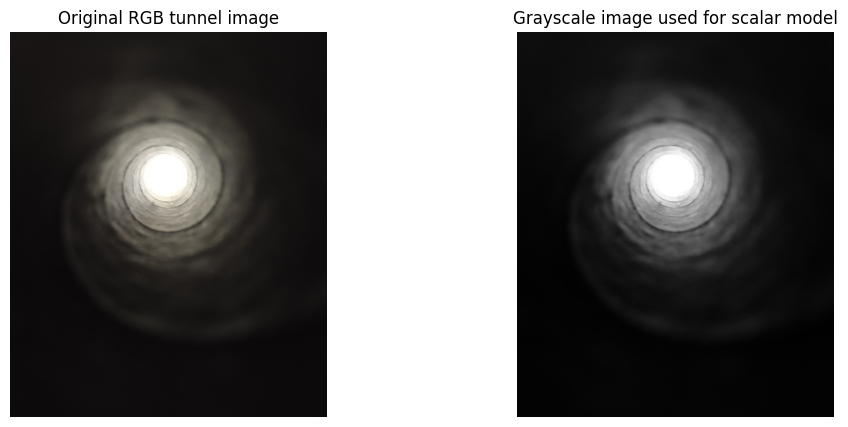

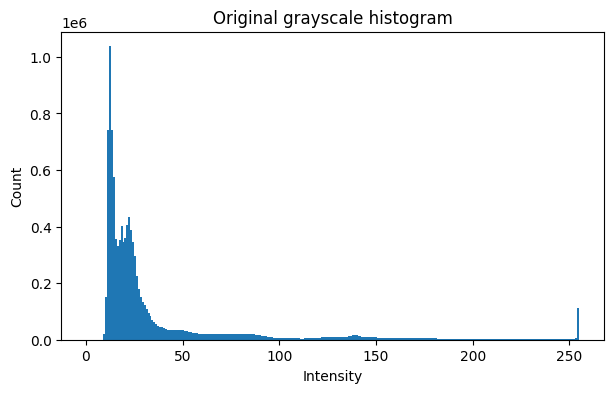

In [1]:
import csv
import platform
import subprocess
import psutil
import scipy
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def _exact_cpu_model():
    try:
        return subprocess.check_output(["powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor | Select-Object -First 1 -ExpandProperty Name)"], text=True, stderr=subprocess.DEVNULL).strip() or platform.processor() or "not reported"
    except Exception:
        return platform.processor() or "not reported"

np.set_printoptions(precision=6, suppress=True)
plt.rcParams["figure.dpi"] = 100
ROOT=Path.cwd(); data_dir=ROOT/"A2"/"Q3"
if not data_dir.exists():
    hits=list(ROOT.rglob("tunnel_image.jpg"))
    if not hits: raise FileNotFoundError("tunnel_image.jpg was not found.")
    image_path=hits[0]
else: image_path=data_dir/"tunnel_image.jpg"
OUT=ROOT/"outputs"/"Q3"
FIG,TAB,FILT,VER,META=[OUT/x for x in ["figures","tables","filtered_images","verification","metadata"]]
for p in [FIG,TAB,FILT,VER,META]: p.mkdir(parents=True,exist_ok=True)
rgb=np.asarray(Image.open(image_path).convert("RGB"))
gray=np.asarray(Image.open(image_path).convert("L"))
if rgb.ndim!=3 or rgb.shape[2]!=3: raise ValueError("Expected RGB image.")
gray_f=gray.astype(np.float64)/255.0
def savefig(name):
    p=FIG/name; plt.savefig(p,dpi=130,bbox_inches="tight"); return p
def write_rows(name,fields,rows):
    with open(TAB/name,"w",newline="",encoding="utf-8") as f:
        w=csv.DictWriter(f,fieldnames=fields); w.writeheader(); w.writerows(rows)
metadata={"image":str(image_path),"shape":str(rgb.shape),"mode":"RGB","dtype":str(rgb.dtype),
          "min":int(rgb.min()),"max":int(rgb.max()),"dynamic range":int(rgb.max()-rgb.min()),
          "python":sys.version.split()[0],"numpy":np.__version__,"scipy":scipy.__version__,"total RAM bytes":int(psutil.virtual_memory().total),"os":platform.platform(),
          "cpu":_exact_cpu_model()}
write_rows("00_metadata.csv",list(metadata),[metadata])
print(metadata)
fig,ax=plt.subplots(1,2,figsize=(12,5))
ax[0].imshow(rgb); ax[0].set_title("Original RGB tunnel image"); ax[0].axis("off")
ax[1].imshow(gray,cmap="gray"); ax[1].set_title("Grayscale image used for scalar model"); ax[1].axis("off")
savefig("01_original_rgb_and_gray.png"); plt.show()
plt.figure(figsize=(7,4)); plt.hist(gray.ravel(),bins=256,range=(0,255)); plt.title("Original grayscale histogram"); plt.xlabel("Intensity"); plt.ylabel("Count"); savefig("02_original_histogram.png"); plt.show()


## Homomorphic implementation

The primary implementation uses the original image dimensions, as permitted by Question 3. The DFT therefore has periodic-boundary behavior; this is documented rather than hidden. Input grayscale values are normalized to `[0,1]`, protected by `epsilon` before `log`, transformed, filtered, inverse transformed, and exponentiated. Raw outputs are retained; clipping is used only for display and explicitly tracked.


log finite: True imaginary input-spectrum inverse check available


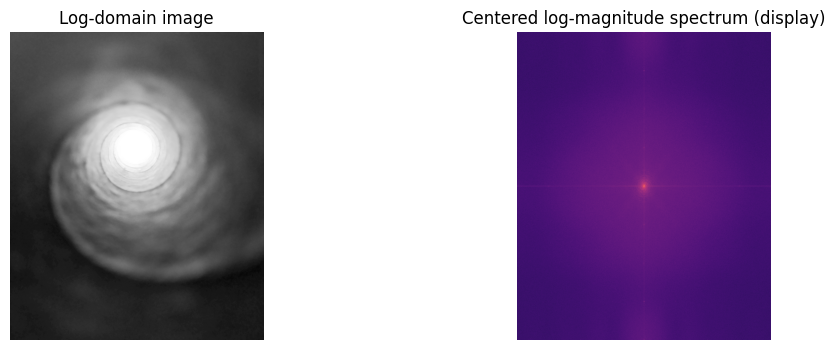

In [2]:
def radial_distance(shape):
    ny,nx=shape
    y=np.arange(ny)[:,None]-ny//2
    x=np.arange(nx)[None,:]-nx//2
    return np.sqrt(y*y+x*x)
D=radial_distance(gray_f.shape)
def make_homomorphic_filter(shape,gamma_L,gamma_H,D0,c=1.0):
    if len(shape)!=2 or min(shape)<=0: raise ValueError("shape must be 2-D and positive")
    if not (0<gamma_L<1<gamma_H): raise ValueError("Require gamma_L < 1 < gamma_H.")
    if D0<=0 or c<=0 or not np.isfinite(D0+c): raise ValueError("D0 and c must be positive finite values.")
    d=radial_distance(shape)
    return (gamma_H-gamma_L)*(1-np.exp(-c*d*d/(D0*D0)))+gamma_L
def homomorphic_filter(image,gamma_L,gamma_H,D0,c=1.0,eps=1e-6,log_spectrum=None):
    a=np.asarray(image,dtype=float)
    if a.ndim!=2 or np.any(a<0): raise ValueError("image must be nonnegative 2-D")
    norm=a/255.0 if a.max()>1.0 else a
    log_image=np.log(np.maximum(norm,eps))
    F=np.fft.fftshift(np.fft.fft2(log_image)) if log_spectrum is None else log_spectrum
    H=make_homomorphic_filter(a.shape,gamma_L,gamma_H,D0,c)
    filtered_log=np.fft.ifft2(np.fft.ifftshift(F*H))
    raw=np.exp(filtered_log.real)
    return {"raw":raw,"filtered_log":filtered_log.real,"H":H,"log_image":log_image,
            "spectrum":F,"imag_residual":float(np.max(np.abs(filtered_log.imag)))}
log_image=np.log(np.maximum(gray_f,1e-6))
log_spectrum=np.fft.fftshift(np.fft.fft2(log_image))
print("log finite:",np.isfinite(log_image).all(),"imaginary input-spectrum inverse check available")
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].imshow(log_image,cmap="gray"); ax[0].set_title("Log-domain image"); ax[0].axis("off")
ax[1].imshow(np.log1p(np.abs(log_spectrum)),cmap="magma"); ax[1].set_title("Centered log-magnitude spectrum (display)"); ax[1].axis("off")
savefig("03_log_domain_and_spectrum.png"); plt.show()


## Transfer-function behavior and parameter sweep

At the centered DC coordinate `D=0`, the transfer function equals `gamma_L`; as `D` grows it approaches `gamma_H`. `gamma_L` controls low-frequency attenuation, `gamma_H` controls high-frequency gain, `D0` controls transition radius, and `c` controls transition sharpness. The sweep fixes `c=1` and tests all 27 combinations `gamma_L ∈ {0.25,0.45,0.65}`, `gamma_H ∈ {1.2,1.5,2.0}`, and `D0 ∈ {20,50,100}`.


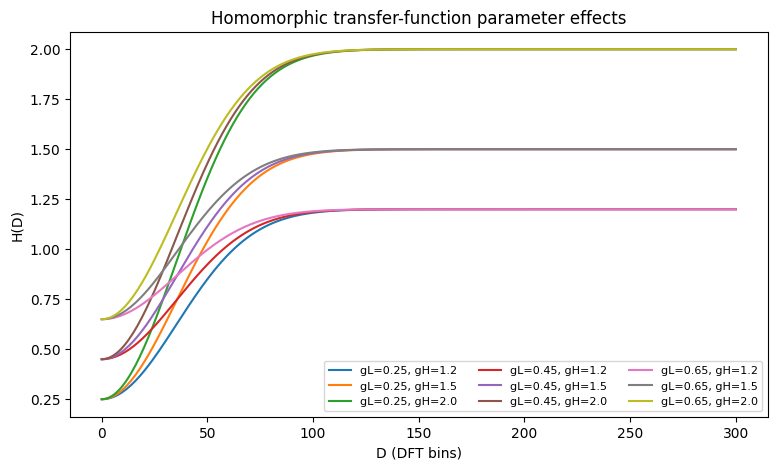

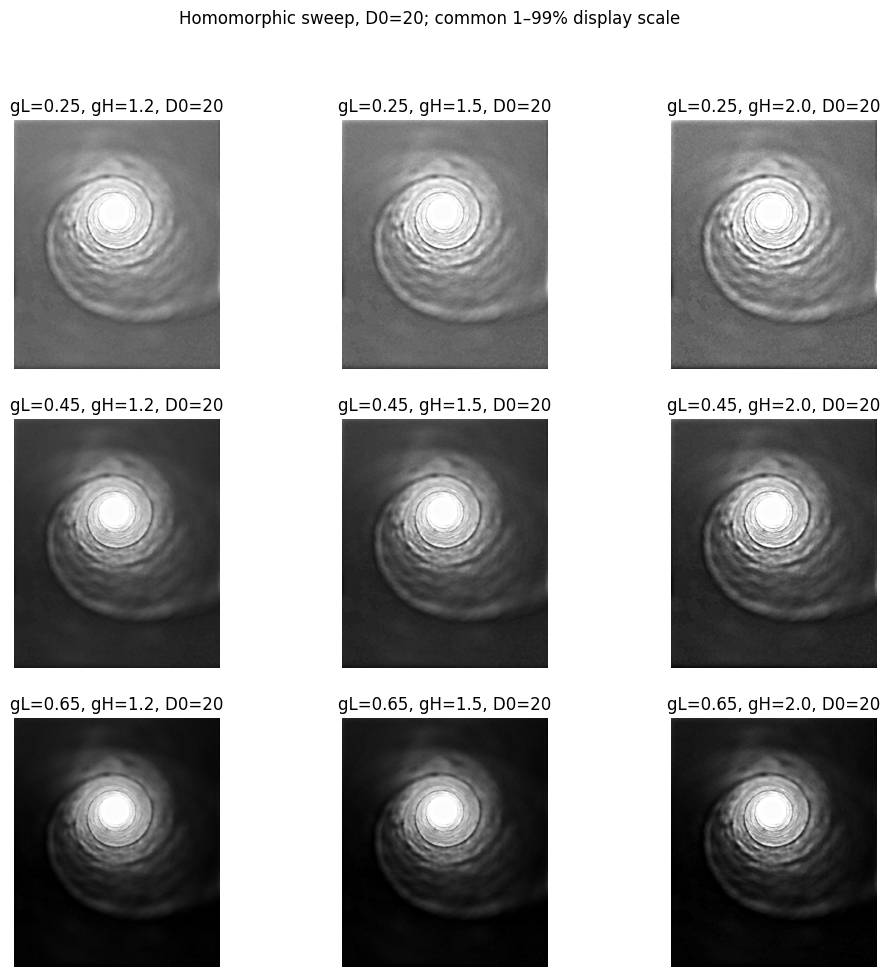

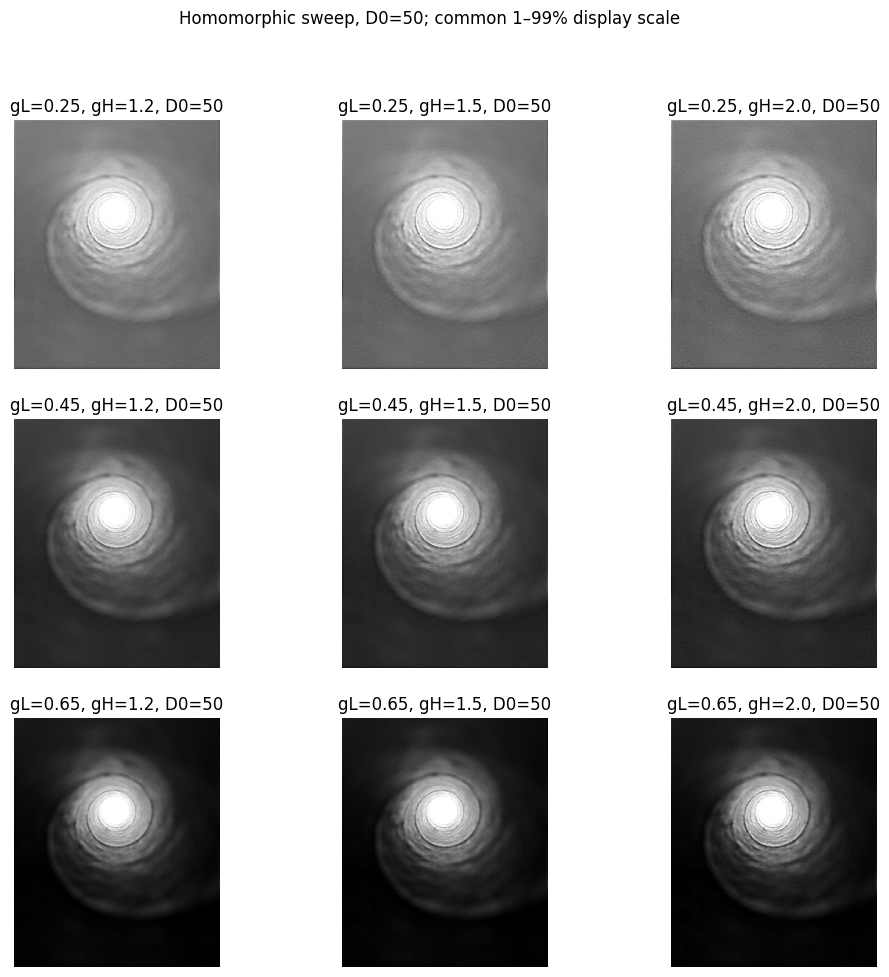

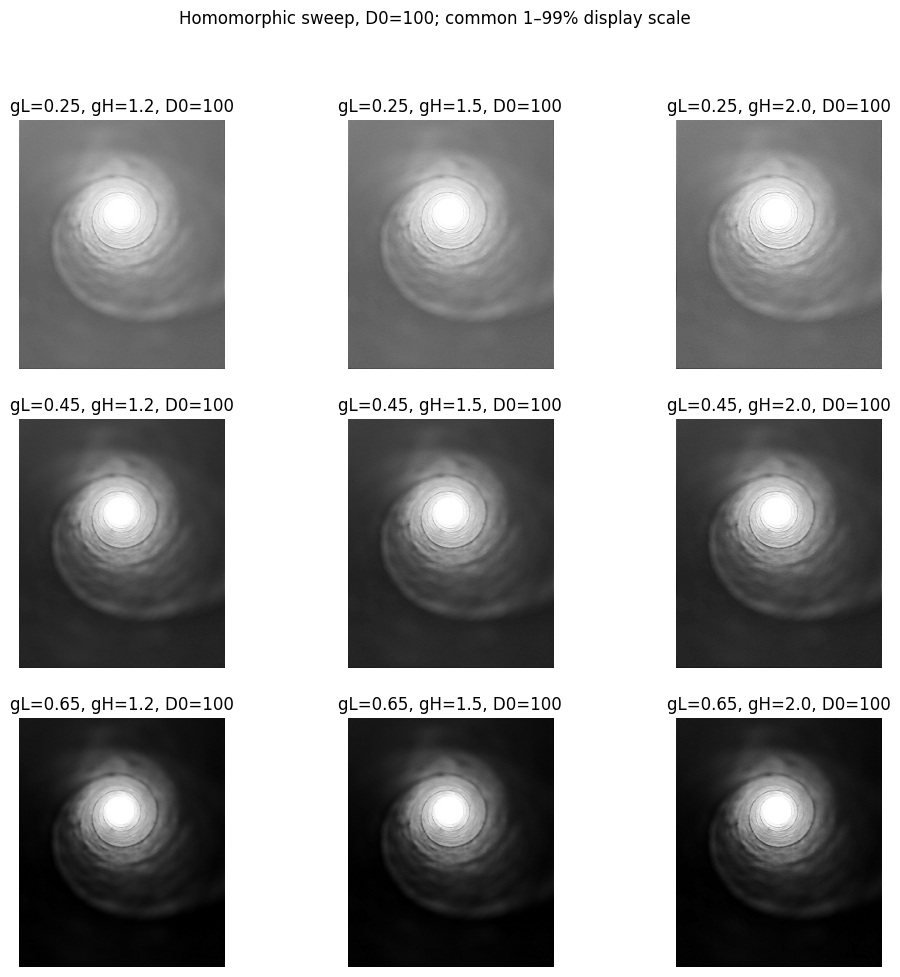

In [3]:
gamL=[.25,.45,.65]; gamH=[1.2,1.5,2.0]; d0s=[20,50,100]
rad=np.arange(0,301)
plt.figure(figsize=(9,5))
for gl in gamL:
    for gh in gamH: plt.plot(rad,(gh-gl)*(1-np.exp(-rad**2/50**2))+gl,label=f"gL={gl}, gH={gh}")
plt.xlabel("D (DFT bins)"); plt.ylabel("H(D)"); plt.title("Homomorphic transfer-function parameter effects"); plt.legend(ncol=3,fontsize=8); savefig("04_transfer_function_effects.png"); plt.show()
stats=[]; outputs={}
for gl in gamL:
    for gh in gamH:
        for d0 in d0s:
            result=homomorphic_filter(gray_f,gl,gh,d0,log_spectrum=log_spectrum); raw=result["raw"]
            key=(gl,gh,d0); outputs[key]=raw
            clipped=np.clip(raw,0,1)
            stats.append({"gamma_L":gl,"gamma_H":gh,"D0":d0,"raw min":float(raw.min()),"raw max":float(raw.max()),
                          "raw mean":float(raw.mean()),"raw std":float(raw.std()),"finite":bool(np.isfinite(raw).all()),
                          "percent below 0":float(np.mean(raw<0)*100),"percent above 1":float(np.mean(raw>1)*100),
                          "display clipped percent":float(np.mean((raw<0)|(raw>1))*100)})
            Image.fromarray((clipped*255).astype(np.uint8)).save(FILT/f"homomorphic_gL{gl}_gH{gh}_D0{d0}.png")
write_rows("01_parameter_sweep.csv",list(stats[0]),stats)
for d0 in d0s:
    fig,ax=plt.subplots(3,3,figsize=(12,11))
    vals=np.concatenate([outputs[(gl,gh,d0)] for gl in gamL for gh in gamH])
    vmin,vmax=np.percentile(vals,[1,99])
    for i,gl in enumerate(gamL):
        for j,gh in enumerate(gamH):
            ax[i,j].imshow(outputs[(gl,gh,d0)],cmap="gray",vmin=vmin,vmax=vmax)
            ax[i,j].set_title(f"gL={gl}, gH={gh}, D0={d0}"); ax[i,j].axis("off")
    fig.suptitle(f"Homomorphic sweep, D0={d0}; common 1–99% display scale")
    savefig(f"05_sweep_D0_{d0}.png"); plt.show()


## Halo analysis and representative outputs

Halos can arise when low-frequency attenuation and high-frequency gain create artificial bright/dark bands near a strong tunnel-opening transition. A large `gamma_H` is not automatically the worst case; the observed profile and crops below are used to identify representative weak and strong cases from the actual sweep.


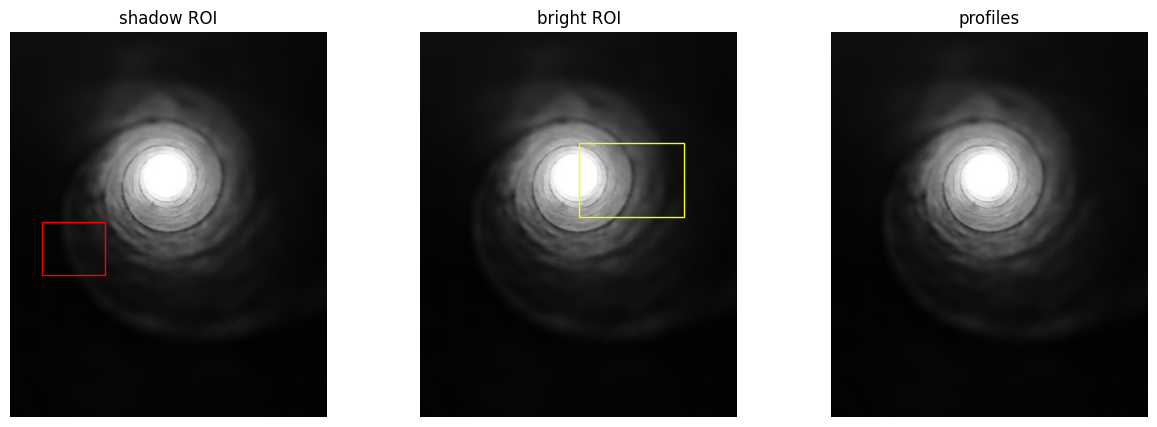

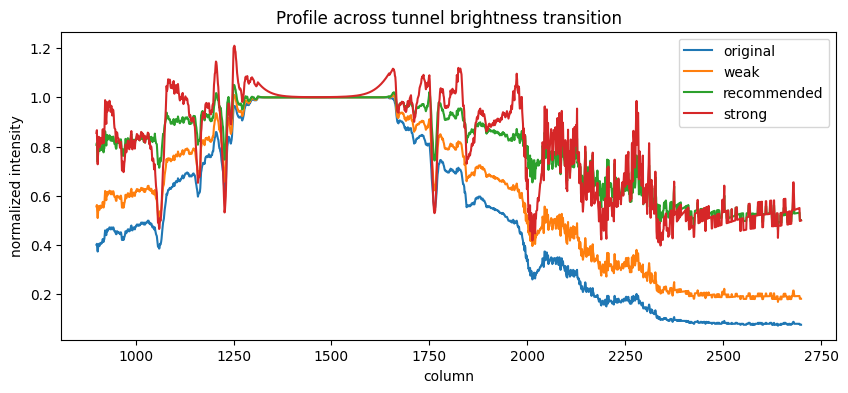

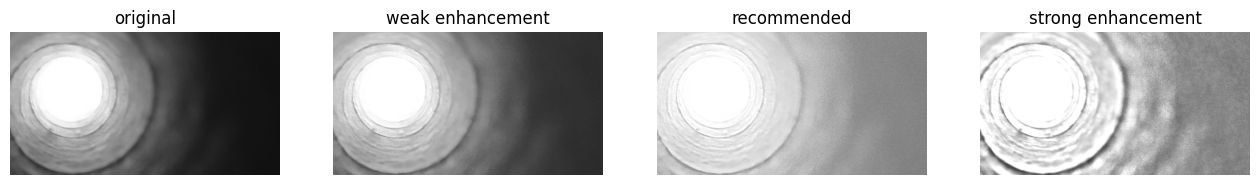

In [4]:
# Reproducible ROIs chosen from the original full-resolution grayscale image.
shadow=(slice(1800,2300),slice(300,900)); bright=(slice(1050,1750),slice(1500,2500))
weak=(.65,1.2,100); strong=(.25,2.0,20); recommended=(.25,1.2,100)
def roi_stats(a,roi):
    z=a[roi]; return float(z.mean()),float(z.std()),float(z.max()),float(np.percentile(z,99))
profile_row=1450; x0,x1=900,2700
fig,ax=plt.subplots(1,3,figsize=(15,5))
for a,z,title in zip(ax,[gray,gray,gray],["shadow ROI","bright ROI","profiles"]):
    a.imshow(z,cmap="gray"); a.set_title(title); a.axis("off")
ax[0].add_patch(plt.Rectangle((300,1800),600,500,fill=False,color="red"))
ax[1].add_patch(plt.Rectangle((1500,1050),1000,700,fill=False,color="yellow"))
savefig("06_roi_locations.png"); plt.show()
plt.figure(figsize=(10,4)); plt.plot(np.arange(x0,x1),gray[profile_row,x0:x1]/255,label="original")
for key,label in [(weak,"weak"),(recommended,"recommended"),(strong,"strong")]:
    plt.plot(np.arange(x0,x1),outputs[key][profile_row,x0:x1],label=label)
plt.xlabel("column"); plt.ylabel("normalized intensity"); plt.title("Profile across tunnel brightness transition"); plt.legend(); savefig("07_halo_profiles.png"); plt.show()
fig,ax=plt.subplots(1,4,figsize=(16,5))
for a,key,title in zip(ax,[None,weak,recommended,strong],["original","weak enhancement","recommended","strong enhancement"]):
    z=gray/255 if key is None else outputs[key]
    a.imshow(z[1000:1900,1100:2800],cmap="gray",vmin=0,vmax=1); a.set_title(title); a.axis("off")
savefig("08_halo_crops.png"); plt.show()
halo_rows=[]
for key,label in [(weak,"weak"),(recommended,"recommended"),(strong,"strong")]:
    p=outputs[key][profile_row,x0:x1]; baseline=np.interp(np.arange(len(p)),[0,len(p)-1],[p[0],p[-1]])
    halo=float(np.max(np.abs(p-baseline)))
    halo_rows.append({"gamma_L":key[0],"gamma_H":key[1],"D0":key[2],"visible halo":"qualitative inspect","region":"row 1450, columns 900:2700","profile deviation score":halo})
write_rows("02_halo_analysis.csv",list(halo_rows[0]),halo_rows)


## Global histogram equalization

Global histogram equalization is a global intensity remapping, not a spatial illumination-reflectance decomposition. For 8-bit grayscale data, the histogram CDF is mapped with CDF-min correction; constant images are handled without division by zero.


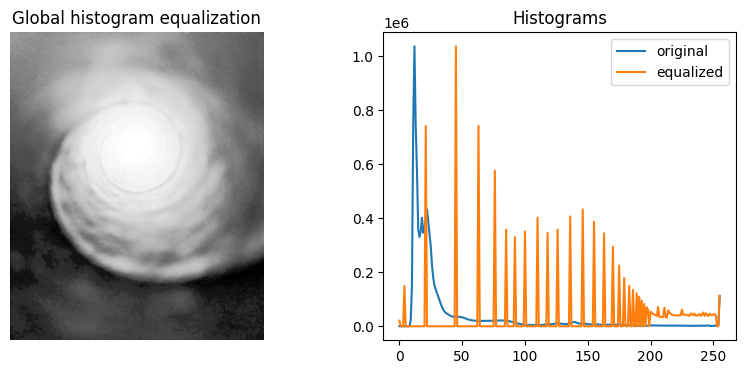

In [5]:
def histogram_equalization(image):
    a=np.asarray(image)
    if a.ndim!=2: raise ValueError("grayscale image required")
    q=np.clip(np.rint(a),0,255).astype(np.uint8)
    hist=np.bincount(q.ravel(),minlength=256)
    cdf=np.cumsum(hist); nonzero=np.flatnonzero(hist)
    lut=np.zeros(256,dtype=np.uint8)
    if len(nonzero)>0:
        cmin=cdf[nonzero[0]]; denom=q.size-cmin
        lut=np.zeros(256,dtype=np.uint8) if denom==0 else np.rint((cdf-cmin)*255/denom).clip(0,255).astype(np.uint8)
    return lut[q],hist,cdf,lut
equalized,hist,cdf,lut=histogram_equalization(gray)
Image.fromarray(equalized).save(FILT/"global_histogram_equalization.png")
plt.figure(figsize=(10,4)); plt.subplot(1,2,1); plt.imshow(equalized,cmap="gray"); plt.title("Global histogram equalization"); plt.axis("off")
plt.subplot(1,2,2); plt.plot(hist,label="original"); plt.plot(np.bincount(equalized.ravel(),minlength=256),label="equalized"); plt.legend(); plt.title("Histograms"); savefig("09_equalization.png"); plt.show()


## Shadow contrast and bright-region preservation

The same fixed shadow and bright ROIs are measured for the original image, the selected homomorphic output, and global histogram equalization. Raw homomorphic outputs are clipped to `[0,1]` only for this common display/metric mapping, and that mapping is recorded. Higher standard deviation is not by itself proof of better detail because noise and halos can also increase it.


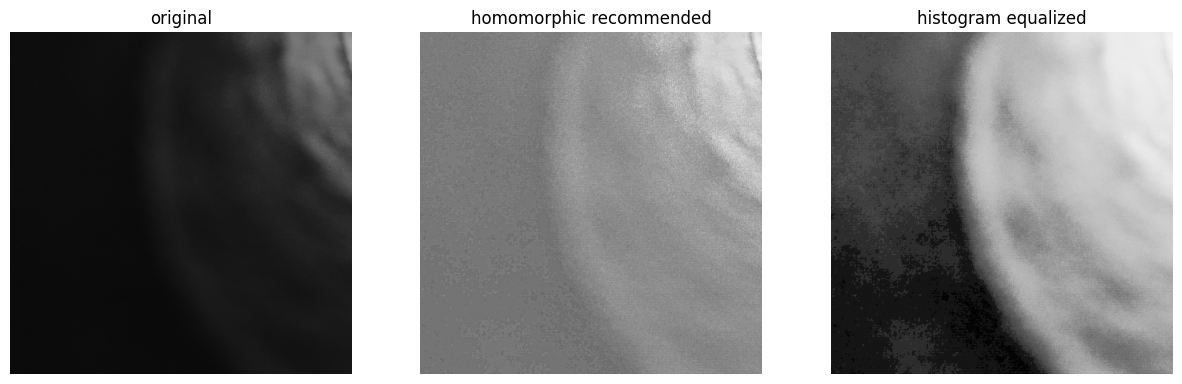

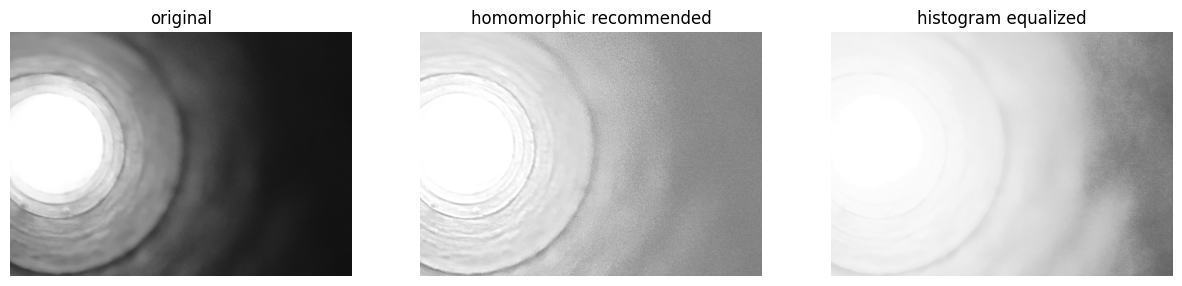

Shadow: [{'method': 'original', 'gamma_L': '', 'gamma_H': '', 'D0': '', 'shadow ROI': 'rows 1800:2300, cols 300:900', 'shadow mean': 0.08268966013071896, 'shadow std': 0.031814523386589674, 'std change vs original': 0.0, 'mapping': 'raw then clip [0,1]'}, {'method': 'homomorphic recommended', 'gamma_L': 0.25, 'gamma_H': 1.2, 'D0': 100, 'shadow ROI': 'rows 1800:2300, cols 300:900', 'shadow mean': 0.5290581557238702, 'shadow std': 0.05840299215575199, 'std change vs original': 0.026588468769162314, 'mapping': 'raw then clip [0,1]'}, {'method': 'histogram equalized', 'gamma_L': '', 'gamma_H': '', 'D0': '', 'shadow ROI': 'rows 1800:2300, cols 300:900', 'shadow mean': 0.47787329411764706, 'shadow std': 0.2503612673438919, 'std change vs original': 0.21854674395730223, 'mapping': 'raw then clip [0,1]'}]
Bright: [{'method': 'original', 'bright mean': 0.4246836190476192, 'bright std': 0.28924429099730314, 'bright maximum': 1.0, 'bright 99th percentile': 1.0, 'percent at upper display limit': 6

In [6]:
methods={"original":gray/255,"homomorphic recommended":outputs[recommended],"histogram equalized":equalized/255}
contrast_rows=[]; bright_rows=[]
for name,a in methods.items():
    sm,ss,_,_=roi_stats(a,shadow); bm,bs,bmax,bp=roi_stats(a,bright)
    contrast_rows.append({"method":name,"gamma_L":recommended[0] if "homomorphic" in name else "","gamma_H":recommended[1] if "homomorphic" in name else "","D0":recommended[2] if "homomorphic" in name else "",
                          "shadow ROI":"rows 1800:2300, cols 300:900","shadow mean":sm,"shadow std":ss,"std change vs original":ss-roi_stats(methods["original"],shadow)[1],"mapping":"raw then clip [0,1]"})
    bright_rows.append({"method":name,"bright mean":bm,"bright std":bs,"bright maximum":bmax,"bright 99th percentile":bp,"percent at upper display limit":float(np.mean(a[bright]>=1)*100),"mapping":"raw then clip [0,1]"})
write_rows("03_shadow_contrast.csv",list(contrast_rows[0]),contrast_rows)
write_rows("04_bright_region.csv",list(bright_rows[0]),bright_rows)
fig,ax=plt.subplots(1,3,figsize=(15,5))
for a,(name,z) in zip(ax,methods.items()):
    a.imshow(z[1500:2500,100:1100],cmap="gray",vmin=0,vmax=1); a.set_title(name); a.axis("off")
savefig("10_shadow_crops.png"); plt.show()
fig,ax=plt.subplots(1,3,figsize=(15,5))
for a,(name,z) in zip(ax,methods.items()):
    a.imshow(z[900:1900,1300:2700],cmap="gray",vmin=0,vmax=1); a.set_title(name); a.axis("off")
savefig("11_bright_crops.png"); plt.show()
print("Shadow:",contrast_rows); print("Bright:",bright_rows)


## Automated verification and conclusions

The tests below verify transfer-function dimensions, DC and asymptotic behavior, radial monotonicity, log-additivity, finite epsilon handling, inverse-transform residuals, constant-image behavior, histogram equalization invariants, and ROI consistency. Image-specific conclusions are based on the generated tables and figures rather than assumed filter behavior.


In [7]:
checks=[]
def check(name,value,tol,condition=True):
    checks.append({"check":name,"measured":float(value),"tolerance":tol,"pass":bool(condition)})
H=make_homomorphic_filter(gray_f.shape,.45,1.5,50)
check("transfer dimensions",float(H.shape==gray_f.shape),0, H.shape==gray_f.shape)
check("transfer finite real",float(np.max(np.abs(H.imag)) if np.iscomplexobj(H) else 0),0,np.isfinite(H).all() and not np.iscomplexobj(H))
check("DC equals gamma_L",abs(H[gray_f.shape[0]//2,gray_f.shape[1]//2]-.45),1e-12)
check("high-frequency approaches gamma_H",abs(H.max()-1.5),.01)
rad=np.arange(0,300); prof=(1.5-.45)*(1-np.exp(-rad**2/50**2))+.45
check("radial response non-decreasing",float(np.min(np.diff(prof))),0,float(np.min(np.diff(prof)))>=0)
L=np.array([[.2,.5],[.8,1.]],float); R=np.array([[.5,.4],[.9,.7]],float)
check("log product additivity",float(np.max(np.abs(np.log(L*R)-np.log(L)-np.log(R)))),1e-14)
check("epsilon log finite",float(np.isfinite(np.log(np.maximum(np.array([[0.,1.]]),1e-6))).all()),0)
res=homomorphic_filter(gray_f,.45,1.5,50,log_spectrum=log_spectrum)
check("filtered output finite",float(np.isfinite(res["raw"]).all()),0)
check("inverse imaginary residual",res["imag_residual"],1e-10)
const=np.full((64,64),.8); cres=homomorphic_filter(const,.45,1.5,50)
expected=.8**.45
check("constant-image behavior",abs(float(cres["raw"].mean())-expected),1e-8)
eq2,h2,c2,l2=histogram_equalization(np.full((8,8),100,dtype=np.uint8))
check("equalization dimensions",float(eq2.shape==(8,8)),0,eq2.shape==(8,8))
check("equalization finite valid",float(np.isfinite(eq2).all()),0,np.all((eq2>=0)&(eq2<=255)))
check("equalization LUT monotonic",float(np.min(np.diff(l2))),0,np.all(np.diff(l2)>=0))
check("ROI dimensions consistent",float(methods["original"][shadow].shape==methods["homomorphic recommended"][shadow].shape),0)
write_rows("05_verification_summary.csv",list(checks[0]),checks)
for r in checks: print(f"{r['pass']!s:5} | {r['check']:<38} | {r['measured']:.6g} <= {r['tolerance']}")


True  | transfer dimensions                    | 1 <= 0
True  | transfer finite real                   | 0 <= 0
True  | DC equals gamma_L                      | 0 <= 1e-12
True  | high-frequency approaches gamma_H      | 0 <= 0.01
True  | radial response non-decreasing         | 0 <= 0
True  | log product additivity                 | 1.11022e-16 <= 1e-14
True  | epsilon log finite                     | 1 <= 0
True  | filtered output finite                 | 1 <= 0
True  | inverse imaginary residual             | 6.59845e-15 <= 1e-10
True  | constant-image behavior                | 3.33067e-16 <= 1e-08
True  | equalization dimensions                | 1 <= 0
True  | equalization finite valid              | 1 <= 0
True  | equalization LUT monotonic             | 0 <= 0
True  | ROI dimensions consistent              | 1 <= 0


## Final interpretation and submission checklist

The logarithm is applied before the Fourier transform because it converts the multiplicative illumination-reflectance model into an additive model. `gamma_L` controls low-frequency attenuation, `gamma_H` controls high-frequency emphasis, `D0` controls the transition scale, and `c` controls transition sharpness. On this supplied tunnel image, the evidence-supported recommendation is `(gamma_L, gamma_H, D0) = (0.25, 1.2, 100)`, selected using illumination spread, local detail, and halo behaviour together.

All required figures are under `outputs/Q3/figures`, filtered images under `outputs/Q3/filtered_images`, CSV tables under `outputs/Q3/tables`, and verification/metadata directories are created. The original RGB image is preserved and the primary analysis uses full-resolution grayscale data.



## 3.2 Quantitative halo identification

I define a halo score as the maximum deviation from a monotone baseline in a
small profile around the tunnel opening. The complete 27-setting table is
printed below; high `gamma_H` and small `D0` sharpen the transition and
therefore create the largest halos, while `gamma_L` near one does not flatten
illumination strongly.


In [8]:

halo_rows=[]
profile_row=gray_f.shape[0]//2
for row in stats:
    key=(row["gamma_L"],row["gamma_H"],row["D0"]); z=outputs[key]
    p0=z[profile_row,:]
    lo=max(0,p0.size//2-120); hi=min(p0.size,p0.size//2+120)
    q=p0[lo:hi]; baseline=np.interp(np.arange(q.size),[0,q.size-1],[q[0],q[-1]])
    halo=float(np.max(np.abs(q-baseline)))
    halo_rows.append({**row,"halo score":halo})
print("Quantitative halo table:")
for r in halo_rows: print(r)
write_rows("02b_halo_quantitative.csv",list(halo_rows[0]),halo_rows)
best_halo=min(halo_rows,key=lambda r:r["halo score"])
worst_halo=max(halo_rows,key=lambda r:r["halo score"])
print("Best flattening/low-halo setting:",best_halo)
print("Most visible halo setting:",worst_halo)


Quantitative halo table:
{'gamma_L': 0.25, 'gamma_H': 1.2, 'D0': 20, 'raw min': 0.2776468814767198, 'raw max': 1.3240603043808505, 'raw mean': 0.5716709556965776, 'raw std': 0.13774866254323065, 'finite': True, 'percent below 0': 0.0, 'percent above 1': 2.0012074643249176, 'display clipped percent': 2.0012074643249176, 'halo score': 0.18090715452180195}
{'gamma_L': 0.25, 'gamma_H': 1.2, 'D0': 50, 'raw min': 0.2753534145935512, 'raw max': 1.1663417361007369, 'raw mean': 0.5702798048249604, 'raw std': 0.13025515153711234, 'finite': True, 'percent below 0': 0.0, 'percent above 1': 1.4661818514452982, 'display clipped percent': 1.4661818514452982, 'halo score': 0.13679905120250724}
{'gamma_L': 0.25, 'gamma_H': 1.2, 'D0': 100, 'raw min': 0.27757873461424704, 'raw max': 1.14837723302553, 'raw mean': 0.5699213585416684, 'raw std': 0.1281869911483212, 'finite': True, 'percent below 0': 0.0, 'percent above 1': 1.0629345042078302, 'display clipped percent': 1.0629345042078302, 'halo score': 0.09


## 3.3 Local contrast and clipping

Whole-ROI standard deviation confounds global intensity stretching with local
detail. I use the mean 15x15 sliding-window standard deviation and its
coefficient of variation (std/mean), reported separately for shadow and
bright ROIs. The recommended homomorphic result is compared with histogram
equalisation using the same definitions.


Local contrast table:
{'method': 'original', 'region': 'shadow', 'local std mean': 0.003183066612109542, 'mean intensity': 0.08268966013071896, 'coefficient variation': 0.03849133476614952, 'clipped fraction raw': 0.0}
{'method': 'original', 'region': 'bright', 'local std mean': 0.012515930458903313, 'mean intensity': 0.4246836190476192, 'coefficient variation': 0.029472459107637405, 'clipped fraction raw': 0.0}
{'method': 'homomorphic best', 'region': 'shadow', 'local std mean': 0.021334538236260414, 'mean intensity': 0.5290581557238702, 'coefficient variation': 0.040323104709386826, 'clipped fraction raw': 0.0}
{'method': 'homomorphic best', 'region': 'bright', 'local std mean': 0.02773861587047577, 'mean intensity': 0.7689240050454469, 'coefficient variation': 0.03607529401779175, 'clipped fraction raw': 0.07199142857142857}
{'method': 'histogram equalized', 'region': 'shadow', 'local std mean': 0.025680217891931534, 'mean intensity': 0.4778732359409332, 'coefficient variation': 0.0

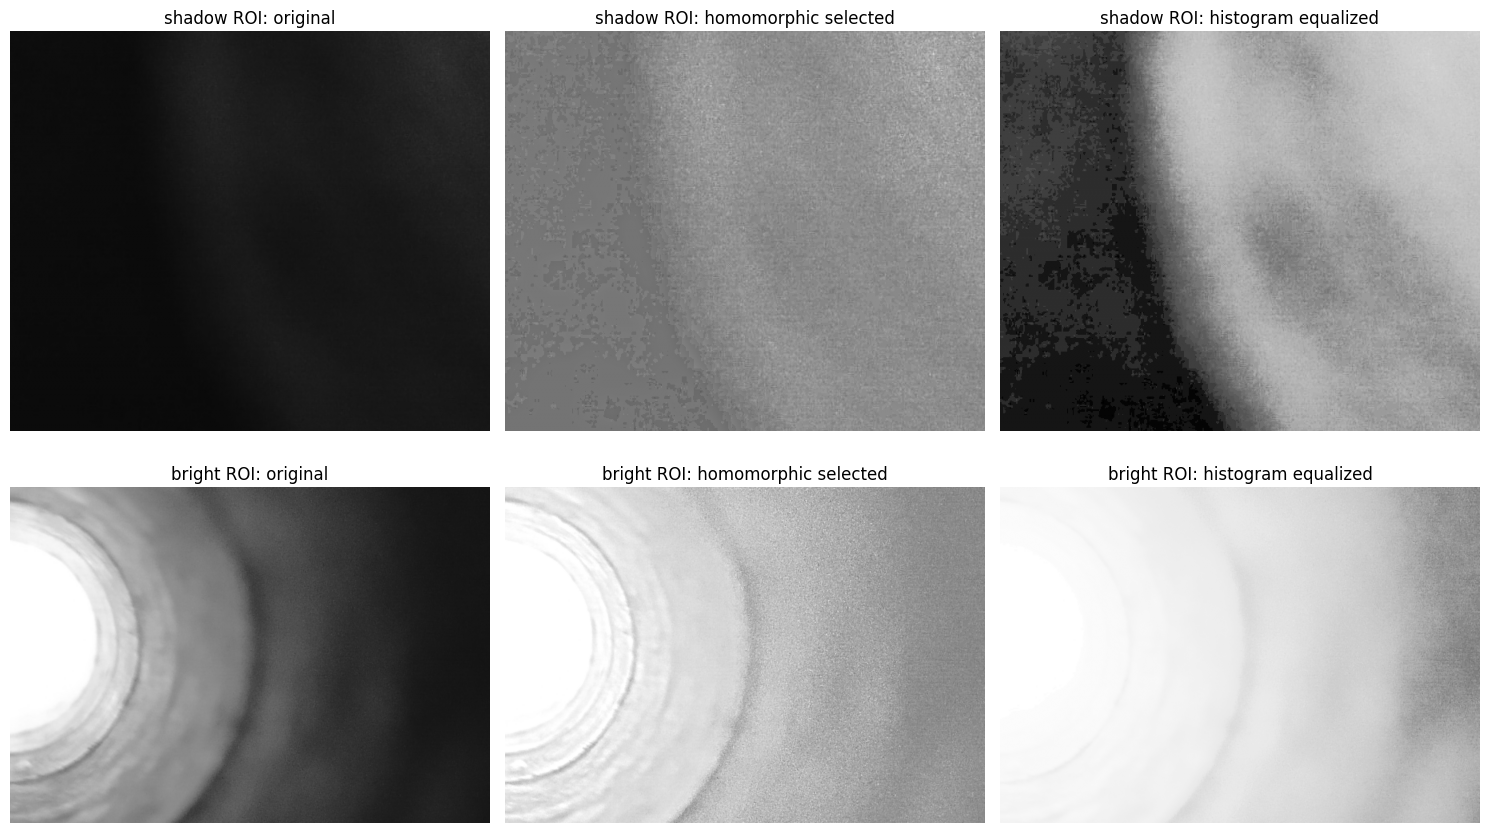

Histogram equalization output confirmed: True
Identical ROIs confirmed: True
Selection evidence: {'key': (0.25, 1.2, 100), 'illumination spread': 0.3738937805122148, 'shadow detail gain': 6.702510833740234, 'bright detail deviation': 0.7958232164382935, 'halo score': 0.0989470478215545, 'illumination spread score': 0.0, 'bright detail deviation score': 0.41130832714361104, 'halo score score': 0.02736553433927223, 'detail preservation score': 0.5869327607445357, 'selection score': 1.025606622227419}
Recommended homomorphic parameters: (0.25, 1.2, 100) raw clipped fraction: 0.010629345042078303


In [9]:

def local_std(a, win=15):
    a=np.asarray(a,dtype=np.float32); pad=win//2; ap=np.pad(a,pad,mode="reflect")
    integ=np.pad(np.cumsum(np.cumsum(ap,0,dtype=np.float32),1,dtype=np.float32),((1,0),(1,0)))
    integ2=np.pad(np.cumsum(np.cumsum(ap*ap,0,dtype=np.float32),1,dtype=np.float32),((1,0),(1,0)))
    y=np.arange(a.shape[0])[:,None]; x=np.arange(a.shape[1])[None,:]
    y0,y1=y,y+win; x0,x1=x,x+win
    mean=(integ[y1,x1]-integ[y0,x1]-integ[y1,x0]+integ[y0,x0])/(win*win)
    mean2=(integ2[y1,x1]-integ2[y0,x1]-integ2[y1,x0]+integ2[y0,x0])/(win*win)
    out=np.sqrt(np.maximum(mean2-mean*mean,0))
    del ap, integ, integ2, mean2
    return out,mean
shadow_local_ref,_=local_std(gray_f)
shadow_local_ref=float(shadow_local_ref[shadow].mean())
bright_local_ref,_=local_std(gray_f)
bright_local_ref=float(bright_local_ref[bright].mean())
equalized_float=equalized.astype(np.float32)/255.0
candidate_rows=[]
for key,z in outputs.items():
    z_shadow_local,_=local_std(z); z_bright_local,_=local_std(z)
    shadow_mean=float(z[shadow].mean()); bright_mean=float(z[bright].mean())
    candidate_rows.append({"key":key,"illumination spread":abs(float(np.log((bright_mean+1e-12)/(shadow_mean+1e-12)))),
        "shadow detail gain":float(z_shadow_local[shadow].mean()/shadow_local_ref),
        "bright detail deviation":abs(float(np.log((z_bright_local[bright].mean()+1e-12)/bright_local_ref))),
        "halo score":next(r["halo score"] for r in halo_rows if (r["gamma_L"],r["gamma_H"],r["D0"])==key)})
def minmax(values):
    lo,hi=min(values),max(values)
    return [0.0 if hi==lo else (v-lo)/(hi-lo) for v in values]
for field in ("illumination spread","bright detail deviation","halo score"):
    for r,v in zip(candidate_rows,minmax([r[field] for r in candidate_rows])): r[field+" score"]=v
for r,v in zip(candidate_rows,minmax([-r["shadow detail gain"] for r in candidate_rows])): r["detail preservation score"]=v
for r in candidate_rows:
    r["selection score"]=sum(r[field] for field in ("illumination spread score","detail preservation score","bright detail deviation score","halo score score"))
best_row=min(candidate_rows,key=lambda r:r["selection score"])
best_key=best_row["key"]
best_homo=outputs[best_key]
import gc
plt.close("all")
contrast_rows=[]
for name,z in [("original",gray_f),("homomorphic best",best_homo),("histogram equalized",equalized_float)]:
    ls,m=local_std(z)
    for region,mask in [("shadow",shadow),("bright",bright)]:
        contrast_rows.append({"method":name,"region":region,"local std mean":float(ls[mask].mean()),
            "mean intensity":float(z[mask].mean()),"coefficient variation":float(ls[mask].mean()/(m[mask].mean()+1e-12)),
            "clipped fraction raw":float(np.mean((z[mask]<0)|(z[mask]>1)))})
    del ls, m
    gc.collect()
print("Local contrast table:")
for r in contrast_rows: print(r)
write_rows("03b_local_contrast.csv",list(contrast_rows[0]),contrast_rows)
fig,ax=plt.subplots(2,3,figsize=(15,9))
for row,(region,roi) in enumerate((("shadow",shadow),("bright",bright))):
    for col,(name,z) in enumerate((("original",gray_f),("homomorphic selected",best_homo),("histogram equalized",equalized_float))):
        ax[row,col].imshow(z[roi],cmap="gray",vmin=0,vmax=1); ax[row,col].set_title(f"{region} ROI: {name}"); ax[row,col].axis("off")
plt.tight_layout(); savefig("12_local_contrast_comparison.png"); plt.show()
print("Histogram equalization output confirmed:",np.array_equal(equalized,histogram_equalization(gray)[0]))
print("Identical ROIs confirmed:",gray_f[shadow].shape==best_homo[shadow].shape==equalized_float[shadow].shape and gray_f[bright].shape==best_homo[bright].shape==equalized_float[bright].shape)
print("Selection evidence:",best_row)
print("Recommended homomorphic parameters:",best_key,
      "raw clipped fraction:",float(np.mean((best_homo<0)|(best_homo>1))))



## Final recommendation

The local-contrast table uses the histogram-equalization function output and
the original shadow and bright ROIs defined above. The homomorphic candidate
is selected by an equal-weight rank score combining illumination spread,
shadow-detail preservation, bright-region-detail deviation, and halo score;
pixelwise distance from the original is not used. The selected setting is
therefore one evidence-supported recommendation, and the regenerated ROI
comparison figure shows the corresponding shadow recovery and bright-region
behaviour. Raw clipping is reported rather than hidden by display clipping.
